In [5]:
import os
import torch

print("CUDA_VISIBLE_DEVICES =", os.environ.get("CUDA_VISIBLE_DEVICES"))
print("CUDA available:", torch.cuda.is_available())
print("Visible device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("Torch device 0 name:", torch.cuda.get_device_name(0))

CUDA_VISIBLE_DEVICES = 1
CUDA available: True
Visible device count: 1
Torch device 0 name: NVIDIA RTX A5000


In [1]:
%load_ext autoreload
%autoreload 2

import logging
import sys
from pathlib import Path
import torch
import numpy as np

logging.basicConfig(level=logging.INFO)

sys.path.insert(0, str(Path.cwd().parents[0]))
sys.path.insert(0, str(Path.cwd().parents[0] / "src"))

# Experiment Setup

In [2]:
EXPERIMENT_NAME = "mixed_loss_sweep"
RESULTS_DIR = Path("../segm/results") / EXPERIMENT_NAME
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

N_RUNS = 15
RUN_BASE_SEED = 12350

print(f"Results will be saved to: {RESULTS_DIR}")
print(f"Number of runs per loss: {N_RUNS}")

Results will be saved to: ../segm/results/mixed_loss_sweep
Number of runs per loss: 15


In [3]:
MODELS_PATH = Path("../segm/models/")

TEST_ROOT = Path("../segm/real_data/test")
REAL_ROOT = Path("../segm/real_data/labeled_wo_test")
SYNTH_ROOT = Path("../segm/fin_data/gen_basic")

# Data Loading

In [4]:
from precipseg import data

LOAD_SYNTH_MODE = "basic"  # "basic" or "clustered"

# only used for "basic"
LOAD_NUM_SYNTH = 450  

# only used for "clustered"
CLUSTERS_BASE_COUNTS = (10, 13, 7, 9, 6)  
CLUSTERS_MULTIPLICATOR = 5
CLUSTERS_DIR_PREFIX = "cl"  # assumes the clustered images were generated like *{prefix}{i}/img.png

# test
test_img_paths, test_label_paths = data.load_paths(TEST_ROOT)
test_imgs = [data.read_image_normalized(p) for p in test_img_paths]
test_labels = [data.read_image_normalized(p) for p in test_label_paths]

# train real
real_img_paths, real_label_paths = data.load_paths(REAL_ROOT)

# train synthetic
if LOAD_SYNTH_MODE == "basic":
    synth_img_paths, synth_label_paths = data.load_paths(SYNTH_ROOT, LOAD_NUM_SYNTH)
elif LOAD_SYNTH_MODE == "clustered":
    synth_img_paths, synth_label_paths = data.load_clustered(SYNTH_ROOT, CLUSTERS_BASE_COUNTS, CLUSTERS_MULTIPLICATOR)
else:
    raise ValueError(f"Unknown LOAD_SYNTH_MODE={LOAD_SYNTH_MODE!r}")


train_img_paths = real_img_paths + synth_img_paths
train_label_paths = real_label_paths + synth_label_paths

print(f"Train: {len(real_img_paths)} real + {len(synth_img_paths)} synthetic ({LOAD_SYNTH_MODE}).")
print(f"Test: {len(test_img_paths)}.")

/home/mvitkovicova/miniconda3/envs/myenv/lib/python3.12/site-packages/albumentations/__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.16). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Train: 45 real + 450 synthetic (basic).
Test: 6.


In [27]:
from precipseg import data

PATCH_SIZE = 256
X_CHANNELS = 3
BATCH_SIZE = 16
VAL_SIZE = 0.25

train_dl, val_dl = data.build_dataloaders(
    train_img_paths, train_label_paths,
    patch_size=PATCH_SIZE,
    x_channels=X_CHANNELS,
    batch_size=BATCH_SIZE,
    val_size=VAL_SIZE,
)

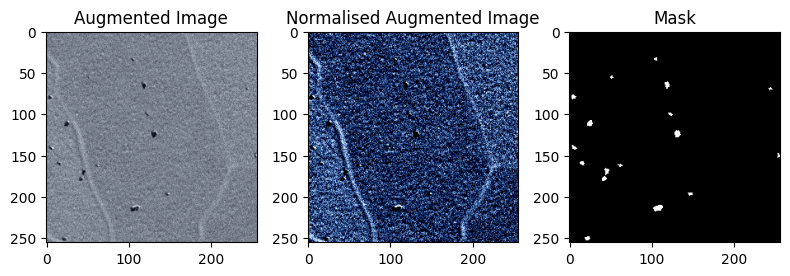

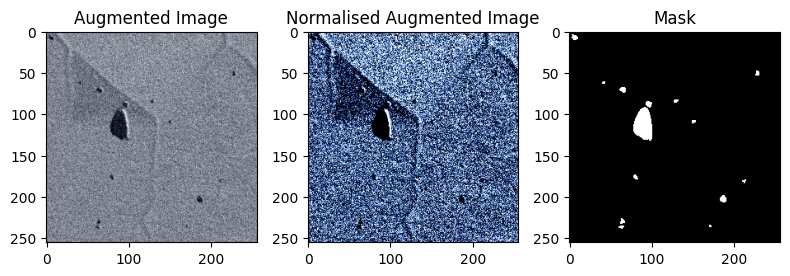

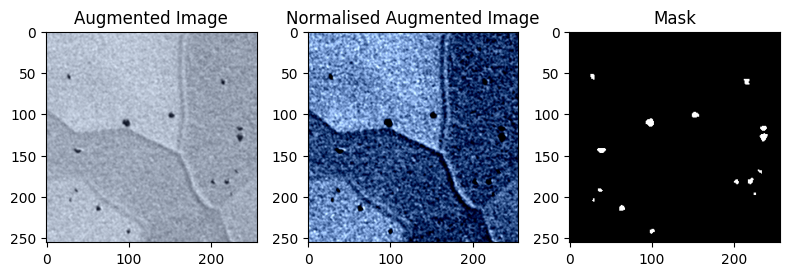

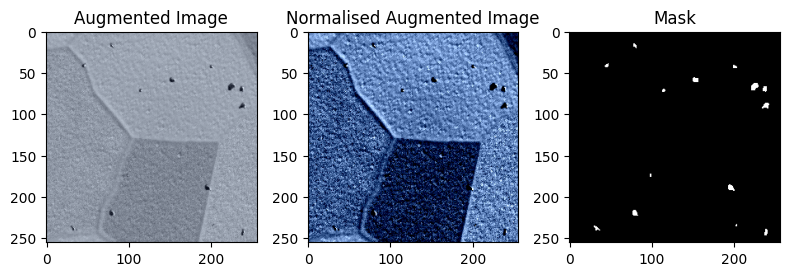

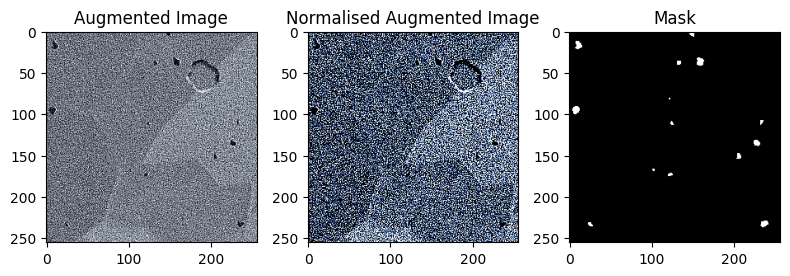

In [28]:
from precipseg.data import show_augmented_triple

show_augmented_triple(n_show=5, train_dl=train_dl)

# Loss Selection

In [29]:
from precipseg.losses import available_losses
from itertools import product

print("Available losses:", available_losses())

LOSS_PARAM_GRID = {
    "focal": dict(
        alpha=[0.3, 0.5, 0.7],
        gamma=[1.5, 2.0, 2.5],
    ),
    "focal_dice": dict(
        alpha=[0.2, 0.4, 0.6],
        gamma=[1.5, 2.0, 2.5],
        smooth=[1e-6],
    ),
    # "focal_tversky": dict(
    #     alpha=[0.3, 0.5, 0.7],
    #     beta=[0.7, 0.5, 0.3],
    #     gamma=[1.3],
    #     bce_weight=[0.3],
    #     smooth=[1e-6],
    # ),
}


# LOSSES = []

# for loss_name, grid in LOSS_PARAM_GRID.items():
#     for values in product(*grid.values()):
#         LOSSES.append({"loss_name": loss_name, "params": dict(zip(grid.keys(), values))})


LOSSES = [
    {"loss_name": "focal_dice", "params": {"alpha": 0.4, "gamma": 2.0, "smooth": 1e-6}},
    {"loss_name": "focal_dice", "params": {"alpha": 0.6, "gamma": 2.5, "smooth": 1e-6}},
    {"loss_name": "focal_dice", "params": {"alpha": 0.4, "gamma": 2.5, "smooth": 1e-6}},
    {"loss_name": "focal_tversky", "params": {"alpha": 0.5, "beta": 0.3, "gamma": 1.3, "bce_weight": 0.3, "smooth": 1e-6}},
    {"loss_name": "focal_tversky", "params": {"alpha": 0.7, "beta": 0.5, "gamma": 1.3, "bce_weight": 0.3, "smooth": 1e-6}},
    {"loss_name": "focal_tversky", "params": {"alpha": 0.7, "beta": 0.3, "gamma": 1.3, "bce_weight": 0.3, "smooth": 1e-6}},
]

print(f"Number of loss configurations: {len(LOSSES)}")

Available losses: ['focal', 'focal_dice', 'focal_tversky']
Number of loss configurations: 6


# Training

In [ ]:
from precipseg.training import load_run_json, has_required_metrics, run_one
from precipseg.training import ImgData


img_data = ImgData(
    train_dl=train_dl,
    val_dl=val_dl,
    test_imgs=test_imgs,
    test_labels=test_labels,
    real_imgs=real_img_paths,
    synth_imgs=synth_img_paths,
    synth_root=SYNTH_ROOT,
)


THRESHOLDS = np.linspace(0.10, 0.95, 10)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

for cfg in LOSSES:
    loss_name = cfg["loss_name"]
    loss_params = cfg["params"]

    tag = f"{loss_name}-" + "-".join(f"{k}{v}" for k, v in loss_params.items())
    runs_dir = RESULTS_DIR / tag
    runs_dir.mkdir(parents=True, exist_ok=True)

    runs = []
    for i in range(N_RUNS):
        run_seed = RUN_BASE_SEED + i
        run_dir = runs_dir / f"seed_{run_seed}"
        run_json = run_dir / "run.json"

        if run_json.exists():
            cached = load_run_json(run_json)
            if has_required_metrics(cached):
                runs.append(cached)
                continue

        runs.append(
            run_one(
                loss_name=loss_name,
                loss_params=loss_params,
                run_seed=run_seed,
                runs_dir=runs_dir,
                x_channels=X_CHANNELS,
                device=DEVICE,
                thresholds=THRESHOLDS,
                max_images=6,
                data=img_data,
            )
        )

Training epochs: 0it [00:00, ?it/s]

Epoch 0: before_val_loss=inf -> 0.51933. Val IoU=0.427.
Epoch 1: before_val_loss=0.51933 -> 0.37210. Val IoU=0.602.
Epoch 2: before_val_loss=0.37210 -> 0.18293. Val IoU=0.742.
Epoch 3: before_val_loss=0.18293 -> 0.10006. Val IoU=0.778.
Epoch 5: before_val_loss=0.10006 -> 0.08575. Val IoU=0.796.
Epoch 6: before_val_loss=0.08575 -> 0.05955. Val IoU=0.841.
Epoch 8: before_val_loss=0.05955 -> 0.05256. Val IoU=0.858.
Epoch 11: before_val_loss=0.05256 -> 0.04862. Val IoU=0.871.
Epoch 15: before_val_loss=0.04862 -> 0.04663. Val IoU=0.872.
Epoch 17: before_val_loss=0.04663 -> 0.04545. Val IoU=0.875.
Epoch 18: before_val_loss=0.04545 -> 0.04394. Val IoU=0.881.
Epoch 19: before_val_loss=0.04394 -> 0.03792. Val IoU=0.891.
Epoch 26: before_val_loss=0.03792 -> 0.03643. Val IoU=0.900.
Training finished at epoch 36: train_loss=0.04672, val_loss=0.03838, val_IoU=0.897


Segmenting: 100%|██████████| 6/6 [00:00<00:00, 29.27it/s]


Training epochs: 0it [00:00, ?it/s]

Epoch 0: before_val_loss=inf -> 0.41773. Val IoU=0.436.
Epoch 1: before_val_loss=0.41773 -> 0.38553. Val IoU=0.696.
Epoch 2: before_val_loss=0.38553 -> 0.14221. Val IoU=0.754.
Epoch 3: before_val_loss=0.14221 -> 0.10449. Val IoU=0.750.
Epoch 4: before_val_loss=0.10449 -> 0.07917. Val IoU=0.806.


# Results Evaluation

In [36]:
from precipseg.evaluation import collect_runs, summarise_config, rank_summaries

grouped_runs = collect_runs(RESULTS_DIR)

config_results = {
    config: summarise_config(run_dfs, config, best_by="dice", out_dir=RESULTS_DIR)
    for config, run_dfs in grouped_runs.items()
}

global_summary = rank_summaries(
    [res["summary_ranked"] for res in config_results.values()],
    out_path=RESULTS_DIR / "global_summary_ranked.csv",
)

print(global_summary[["rank", "config", "n_runs", "best_threshold", "best_dice_mean", "best_dice_std", "best_f1_mean", "best_f1_std"]].head(5).to_string(index=False))

 rank                                                            config  n_runs  best_threshold  best_dice_mean  best_dice_std  best_f1_mean  best_f1_std
    1 focal_tversky-alpha0.5-beta0.3-gamma1.3-bce_weight0.3-smooth1e-06      20            0.95          0.7321         0.0072        0.7321       0.0072
    2                          focal_dice-alpha0.4-gamma2.0-smooth1e-06      20            0.95          0.7304         0.0086        0.7304       0.0086
    3 focal_tversky-alpha0.7-beta0.5-gamma1.3-bce_weight0.3-smooth1e-06      20            0.95          0.7301         0.0069        0.7301       0.0069
    4 focal_tversky-alpha0.7-beta0.3-gamma1.3-bce_weight0.3-smooth1e-06      20            0.95          0.7165         0.0408        0.7165       0.0408
    5                          focal_dice-alpha0.6-gamma2.5-smooth1e-06      20            0.95          0.7154         0.0359        0.7154       0.0359


In [9]:
import json
from pathlib import Path

import numpy as np
import torch
from segmentation_models_pytorch import Unet

from src.precipseg.data import read_image_normalized
from src.precipseg.predictions import segment_many
from src.precipseg.metrics import compute_metric_curves, save_metric_curves


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
THRESHOLDS = np.linspace(0.10, 0.95, 10)
X_CHANNELS = 3

def load_model(run_dir: Path):
    checkpoint_path = run_dir / "checkpoint.pt"

    obj = torch.load(checkpoint_path, map_location=DEVICE)

    if isinstance(obj, torch.nn.Module):
        model = obj
    else:
        model = Unet(
            encoder_name="resnet18",
            encoder_weights=None,
            in_channels=X_CHANNELS,
            classes=1,
            activation=None,
        )
        model.load_state_dict(obj)

    model.to(DEVICE)
    model.eval()
    return model


def recompute_run(run_dir: Path, thresholds):
    print(f"Processing {run_dir}")

    model = load_model(run_dir)

    preds = segment_many(model, test_imgs, device=DEVICE, x_channels=X_CHANNELS)
    dice, iou, precision, recall, f1 = compute_metric_curves(test_labels, preds, thresholds, 500, -0.01)

    out_path = run_dir / "metrics_recomputed.txt"

    save_metric_curves(out_path, thresholds, dice, iou, precision, recall, f1)

    del model
    del preds  # if stored
    torch.cuda.empty_cache()
    import gc
    gc.collect()


def main(root_dir: str):
    root = Path(root_dir)

    run_dirs = sorted([p.parent for p in root.rglob("checkpoint.pt")])

    for run_dir in run_dirs:
        try:
            recompute_run(run_dir, THRESHOLDS)

        except Exception as e:
            print(f"FAILED {run_dir}: {e}")


if __name__ == "__main__":
    main(Path("../segm/results/real_loss_sweep/loss_sweep1/focaldice-alpha0.4-gamma2.0-smooth1e-06"))

Processing ../segm/results/real_loss_sweep/loss_sweep1/focaldice-alpha0.4-gamma2.0-smooth1e-06/seed_12345


Metric thresholds: 100%|██████████| 10/10 [00:01<00:00,  7.28it/s]


Processing ../segm/results/real_loss_sweep/loss_sweep1/focaldice-alpha0.4-gamma2.0-smooth1e-06/seed_12346


Metric thresholds:  20%|██        | 2/10 [00:00<00:01,  5.17it/s]


KeyboardInterrupt: 